In [1]:
# Imports

import os
import struct   # handles binary data
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Create a decoder function

def read_ai(path):
    
    print(f"Reading and decoding binary file: {path}")

    points = []
    try:
        with open(path, "rb") as f:
            version = struct.unpack("i", f.read(4))[0]  # detects file version, 7 has 16 byte header, 12 has 12 bytes
            print(f'Detected file version: {version}')

            
            # Detect version
            if version == 7:
                print('Using Version 7 file format.')
                count = struct.unpack('i', f.read(4))[0]
                header_size = 16

            else:
                print(f'Using legacy file format (Version {version}).')
                f.seek(12)
                count = struct.unpack('i', f.read(4))[0]
                header_size = 16

            print(f'Header indicated {count} data points')
            if count <= 0:
                print('ERROR: Point count is zero or negative. Cannot proceed.')
                return None
        

            # Data reading
            f.seek(header_size) # move pointer to the start
            points = []
            for i in range(count):  # each point consists of 6 floating-point numbers (6 * 4 = 24 bytes). We only care about the first three: x, y and z.
                record_data = f.read(20)
                if len(record_data) < 20:
                    print(f'WARNING: File ended unexpectedly at point {i+1}.')
                    break

                x, y, z, = struct.unpack("fff", record_data[:12])  # "fff" = unpack 3 consecutive floats (x, y, z)
                points.append([x, -z, y])    # in AC, y = vertical and z = depth, in matplotlib it's reversed, so we switch

            return points
        
    except FileNotFoundError:
        print(f"\nError: File not found at '{path}'")
        return None
    
    except Exception as e:
         print(f"\nAn error occurred while reading the file: {e}")
         return None


Reading and decoding binary file: h:\My Drive\Cranfield\11. Individual Thesis\Code\Coordinates\donington_gp.ai
Detected file version: 7
Using Version 7 file format.
Header indicated 2499 data points

Successfully created pandas DataFrame:
            x          y          z
0 -293.896210 -52.127724  92.400391
1 -295.438446 -51.934586  92.377472
2 -296.979919 -51.741627  92.354691
3 -298.518372 -51.546940  92.332047
4 -300.052185 -51.349022  92.309540

--> Calculated Total Track Length: 3.892 km
--> Export cancelled by user.

Generating 2D verification plot...


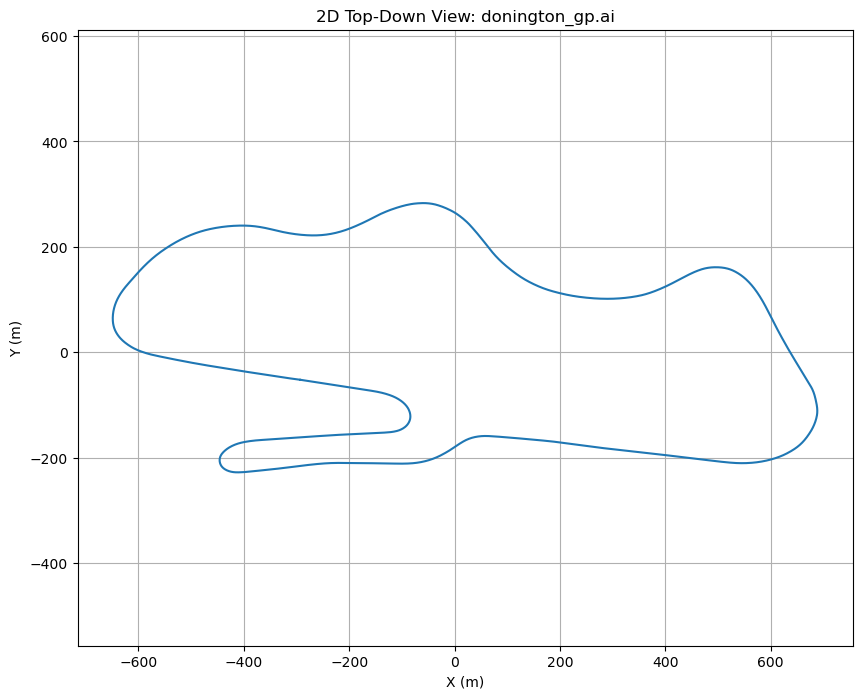


Generating 3D plot...


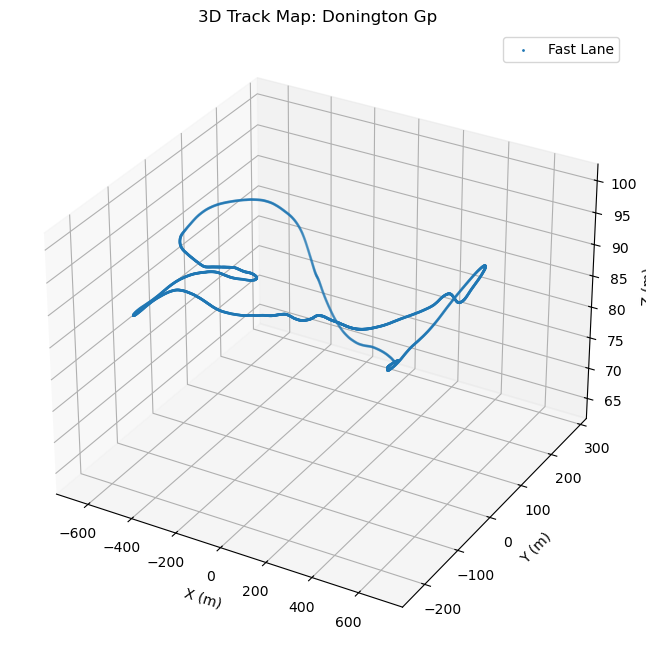

In [3]:
# Conversion & plotting

if __name__ == "__main__":

    EXPORT_TO_CSV = True   # CHANGE TO TRUE TO EXPORT COORDINATES

    track_folder = "Coordinates"
    track_file = "donington_gp.ai"    # CHANGE FOR DIFFERENT TRACK
    current_dir = os.getcwd()
    file_path = os.path.join(current_dir, track_folder, track_file)  # full path
    
    track_points = read_ai(file_path)

    if track_points:    # proceeds only if file read successfully
        track_df = pd.DataFrame(track_points, columns=['x', 'y', 'z'])
        print("\nSuccessfully created pandas DataFrame:")
        print(track_df.head())

        diffs = track_df.diff().dropna() # .diff() finds the difference, .dropna() removes the first row which is NaN
        # Use Pythagorean theorem for 3D distance: sqrt(dx^2 + dy^2 + dz^2)
        segment_lengths = (diffs**2).sum(axis=1)**0.5
        # Sum all the segment lengths to get the total
        total_length_km = segment_lengths.sum() / 1000 # Convert from meters to kilometers
        
        print(f"\n--> Calculated Total Track Length: {total_length_km:.3f} km")

        # export
        if EXPORT_TO_CSV:
            csv_name = os.path.splitext(track_file)[0] + ".csv"
            csv_path = os.path.join(current_dir, track_folder, csv_name)

            if os.path.exists(csv_path):
                overwrite = input(f"--> WARNING: '{csv_path}' already exists. Overwrite? (y/n): ").lower()
                if overwrite != 'y':
                    print('--> Export cancelled by user.')
                else:
                    print(f'--> Overwriting and exporting data to: "{csv_path}"')
                    track_df.to_csv(csv_path, index=False)
                    print('--> Export complete.')
            else:
                print(f'--> Exporting data to: "{csv_path}"')
                track_df.to_csv(csv_path, index=False)
                print('--> Export complete.')


        # plotting 2D map
        print('\nGenerating 2D verification plot...')
        plt.figure(figsize=(10,8))
        plt.plot(track_df['x'], track_df['y'])
        plt.title(f'2D Top-Down View: {track_file}')
        plt.xlabel('X (m)')
        plt.ylabel('Y (m)')
        plt.grid(True)
        plt.axis('equal')   # to preserve track shape
        plt.show()


        # plotting 3D map
        print("\nGenerating 3D plot...")
        fig = plt.figure(figsize=(12, 8))
        ax = fig.add_subplot(projection='3d')

        plot_title = os.path.splitext(track_file)[0].replace("_", " ").title()  # makes title neater
        
        ax.scatter(track_df['x'], track_df['y'], track_df['z'], s=1, label='Fast Lane')
        ax.set_title(f'3D Track Map: {plot_title}')
        ax.set_xlabel('X (m)')
        ax.set_ylabel('Y (m)')
        ax.set_zlabel('Z (m)')

        ax.set_aspect('auto')
        ax.legend()
        ax.grid(True)
        plt.show


